# Deutsch-Jozsa Algorithm

**Course**: Quantum Computing Laboratory
**Version**: 2.2
**Last Updated**: November 2025

---

Demonstrates quantum advantage: solve in ONE query what classically requires multiple queries.

## Theory

Given: Black-box function f:{0,1}ⁿ → {0,1}
Determine: Is f constant or balanced?
- **Constant**: same output for all inputs
- **Balanced**: half 0s, half 1s

**Classical**: Need 2ⁿ⁻¹+1 queries
**Quantum**: Need 1 query!

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister   # circuits built from named registers
from qiskit_aer import AerSimulator                                 # local classical simulator of a quantum computer
from qiskit_aer.primitives import SamplerV2                         # Aer's Sampler primitive: bitstrings per classical register
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # transpiler: circuit -> backend gates
from qiskit.visualization import plot_histogram                     # bar chart of measurement counts
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

print('✓ Qiskit 2.2 ready')


✓ Qiskit 2.2 ready


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QuantumRegister` / `ClassicalRegister` | named registers: n input qubits + 1 ancilla, and n classical bits called `meas` (the Sampler returns the counts under that name) |
| `SamplerV2` + `generate_preset_pass_manager` | the Qiskit 2 execution pattern: transpile for the backend, sample bitstrings, read `result[0].data.meas` |
| `draw(qc)` | our helper around `qc.draw("mpl", style="clifford")`; `display(...)` shows the figure from anywhere in a cell |

</details>


## Implementation

Circuit depth: 7


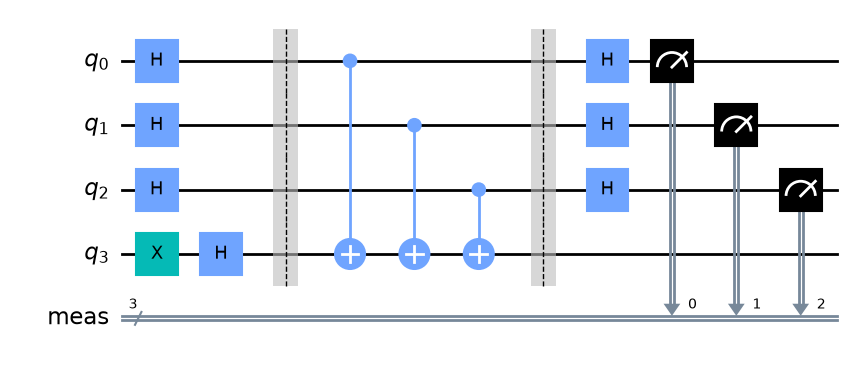

↑ the balanced oracle f(x) = x0 ⊕ x1 ⊕ x2: X + H on the ancilla (bottom), H on the inputs, three CNOTs into the ancilla, H on the inputs again, measurement of the inputs only


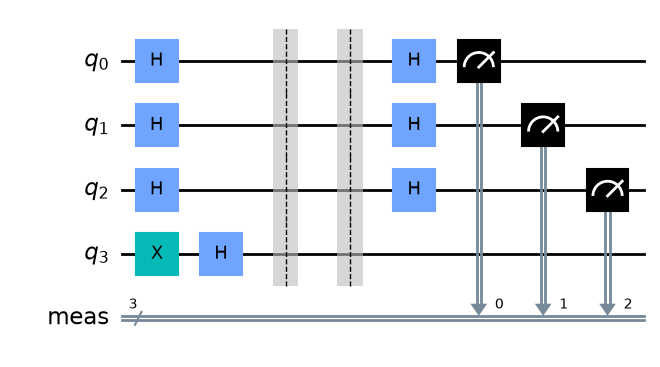

↑ the constant oracle (identity): the two layers of H cancel and the inputs come back to |000⟩


In [2]:
def deutsch_jozsa(n, oracle_type='balanced'):
    qr = QuantumRegister(n+1, 'q')               # n input qubits + 1 ancilla (qubit n)
    cr = ClassicalRegister(n, 'meas')            # only the n input qubits are measured
    qc = QuantumCircuit(qr, cr)

    # Initialize
    qc.x(n)  # Ancilla to |1⟩                     # so that the next H makes it |-> = (|0> - |1>)/sqrt2
    qc.h(range(n+1))  # All to superposition      # inputs -> uniform superposition of all 2^n strings, ancilla -> |->
    qc.barrier()

    # Oracle
    if oracle_type == 'balanced':
        for i in range(n):
            qc.cx(i, n)                          # f(x) = x_0 XOR x_1 XOR ... : balanced; each CNOT kicks the phase (-1)^{x_i} back onto the inputs
    # (constant oracle = identity)

    qc.barrier()
    qc.h(range(n))  # Hadamard                   # interference: constant f -> all amplitude on |00..0>, balanced f -> none
    qc.measure(range(n), range(n))               # qubit i -> classical bit i

    return qc

# Test
qc = deutsch_jozsa(3, 'balanced')
print(f'Circuit depth: {qc.depth()}')
display(draw(qc)); print("↑ the balanced oracle f(x) = x0 ⊕ x1 ⊕ x2: X + H on the ancilla (bottom), H on the inputs, three CNOTs into the ancilla, H on the inputs again, measurement of the inputs only")
display(draw(deutsch_jozsa(3, 'constant'))); print("↑ the constant oracle (identity): the two layers of H cancel and the inputs come back to |000⟩")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc.x(n); qc.h(range(n+1))` | the ancilla is prepared in \|−⟩ = (\|0⟩ − \|1⟩)/√2 — the state that turns an XOR into a *phase*: an oracle that flips the ancilla when f(x) = 1 multiplies the branch x by (−1)^f(x) (**phase kickback**) |
| `qc.cx(i, n)` for every input | the balanced oracle f(x) = x₀ ⊕ x₁ ⊕ x₂ written as three CNOTs into the ancilla; the constant oracle is simply nothing |
| `qc.h(range(n))` after the oracle | the interference step: the amplitude of \|00…0⟩ becomes the average of (−1)^f(x) over all x — 1 for a constant f, 0 for a balanced f |
| `qc.measure(range(n), range(n))` | only the inputs are read; the ancilla is left alone (it is still \|−⟩) |
| `depth 7` | the quantum algorithm asks the oracle **once**; a classical algorithm needs up to 2ⁿ⁻¹ + 1 = 5 queries for n = 3 |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Phase kickback.** With the ancilla in $|-\rangle$, an oracle $U_f|x\rangle|y\rangle=|x\rangle|y\oplus f(x)\rangle$ acts as

$$U_f\,|x\rangle|-\rangle=|x\rangle\,\frac{|f(x)\rangle-|1\oplus f(x)\rangle}{\sqrt2}=(-1)^{f(x)}\,|x\rangle|-\rangle ,$$

so the ancilla is untouched and the input branch $x$ acquires the sign $(-1)^{f(x)}$. After the first Hadamards the inputs are $\frac{1}{\sqrt{2^n}}\sum_x|x\rangle$; after the oracle, $\frac{1}{\sqrt{2^n}}\sum_x(-1)^{f(x)}|x\rangle$; the final Hadamards give

$$\frac{1}{2^n}\sum_{z}\Big[\sum_x(-1)^{f(x)+x\cdot z}\Big]|z\rangle,\qquad\text{amplitude of }|0\ldots0\rangle=\frac{1}{2^n}\sum_x(-1)^{f(x)} .$$

Constant $f$: the sum is $\pm2^n$, amplitude $\pm1$, the measurement gives $000$ with certainty. Balanced $f$: the sum is $0$, so $000$ **never** appears.

For this oracle, $f(x)=x_0\oplus x_1\oplus x_2=s\cdot x$ with $s=111$, and $\sum_x(-1)^{s\cdot x+z\cdot x}=2^n\,\delta_{z,s}$: all the amplitude lands on $|z\rangle=|111\rangle$ (the Bernstein–Vazirani reading of the same circuit). The ideal simulator therefore prints $\{111: 1024\}$ — 1024 shots, one string.

</details>


## Execute

Results:
  counts: {'111': 1024}
  Function is BALANCED ✓


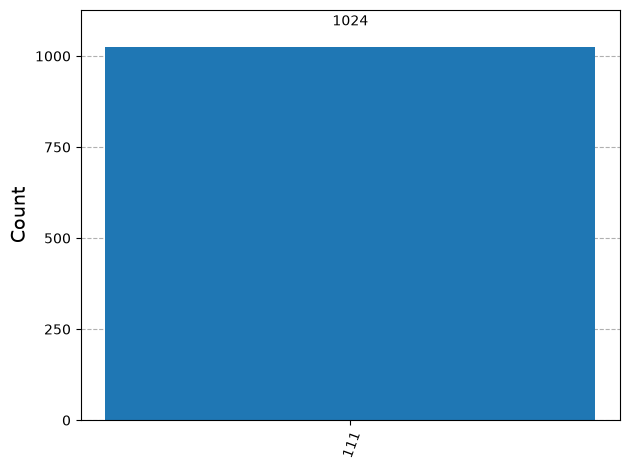

In [3]:
simulator = AerSimulator()                      # ideal local simulator
sampler = SamplerV2()                           # Aer's Sampler primitive
pm = generate_preset_pass_manager(optimization_level=1, backend=simulator)
transpiled = pm.run(qc)                         # ISA circuit for Aer (nothing to change here)

job = sampler.run([transpiled], shots=1024)     # 1024 repetitions of the one-query algorithm
result = job.result()
counts = result[0].data.meas.get_counts()       # the 'meas' register: keys 'q2 q1 q0'

def run_circuit(circuit, shots=1024):
    """Transpile + run + counts in one call (used by the In-depth analysis)."""
    return simulator.run(pm.run(circuit), shots=shots).result().get_counts()

print('Results:')
print('  counts:', dict(counts))                # all 1024 shots on one string for the ideal circuit; spread by noise on hardware
if '000' in counts and counts['000'] > 900:     # (ideal threshold: on noisy hardware use a majority rule, see the In-depth analysis)
    print('  Function is CONSTANT ✓')
else:
    print('  Function is BALANCED ✓')

plot_histogram(counts)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `sampler.run([transpiled], shots=1024)` | 1024 shots, although **one** would do: the ideal circuit is deterministic — the shots only show that the outcome never changes |
| `result[0].data.meas.get_counts()` | the counts of the register named `meas`: `{'111': 1024}` for the balanced oracle, `{'000': 1024}` for the constant one |
| `counts['000'] > 900` | the decision rule of the author, written for an ideal simulator; on a noisy backend the constant oracle may fall a little short of 900/1024, so the In-depth analysis uses a majority rule instead |
| `run_circuit(circuit, shots)` | the same backend in one call, for the In-depth analysis |

</details>


## Analysis

**Key Result**: Measurement of all 0s → constant, otherwise → balanced

**Quantum Advantage**: 1 query vs exponential classical queries

---

**Version**: 2.2.0  
**License**: MIT

## 🔬 In-depth analysis

Write a version `dj_general(n, oracle)` of the circuit whose oracle is a function `oracle(qc, n)` adding gates to the circuit (inputs 0 … n−1, ancilla n), and a `verdict(counts)` that decides CONSTANT / BALANCED by a **majority rule** (fraction of `000` above 1/2) so that it also works on noisy hardware. Then, with 3 inputs and the `run_circuit(circuit, shots)` helper of the Execute cell:

1. Run the constant oracle f = 0 (no gates) and check the verdict.
2. Run the constant oracle f = 1 (an X on the ancilla). The ancilla is flipped — why is the result still `000`?
3. Run the balanced oracle f(x) = x₀ (a single CNOT from input 0 to the ancilla). Which string comes out, and how does it relate to f?

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [4]:
# 🔬 In-depth analysis — your code here



(1) constant f = 0  (no gates): most frequent 000 (1024/1024 shots), fraction of 000 = 1.00 -> CONSTANT
(2) constant f = 1  (X on the ancilla): most frequent 000 (1024/1024 shots), fraction of 000 = 1.00 -> CONSTANT
(3) balanced f = x0 (one CNOT): most frequent 001 (1024/1024 shots), fraction of 000 = 0.00 -> BALANCED


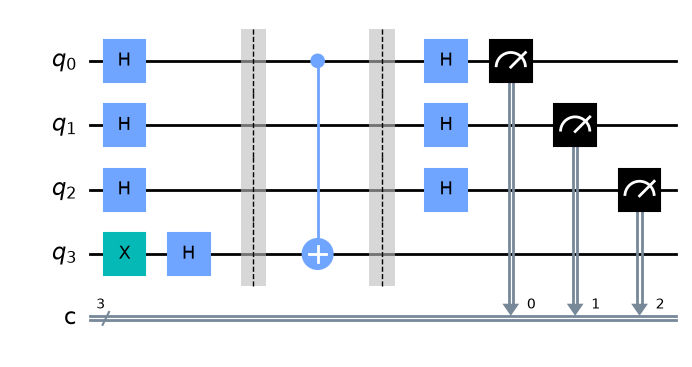

↑ task 3: a single CNOT from input 0 to the ancilla; the output string 001 is the mask s = 001 of f(x) = s·x (Bernstein–Vazirani)


In [5]:
# Reference solution
def dj_general(n, oracle):
    """Deutsch-Jozsa with a user-supplied oracle(qc, n): same layout as deutsch_jozsa()."""
    qc = QuantumCircuit(n + 1, n)                 # inputs 0..n-1, ancilla n; n classical bits
    qc.x(n); qc.h(range(n + 1)); qc.barrier()     # ancilla |->, inputs in uniform superposition
    oracle(qc, n); qc.barrier()                   # the black box, supplied by the caller
    qc.h(range(n)); qc.measure(range(n), range(n))
    return qc

def verdict(counts):
    """Majority rule: CONSTANT if more than half of the shots are 000, else BALANCED."""
    total = sum(counts.values())
    n = len(next(iter(counts)))                   # length of the bitstrings
    frac0 = counts.get('0' * n, 0) / total        # .get(key, 0): 0 if the string never appeared
    top = max(counts, key=counts.get)             # the most frequent string
    return top, frac0, ('CONSTANT' if frac0 > 0.5 else 'BALANCED')

oracles = {
    '(1) constant f = 0  (no gates)':        lambda qc, n: None,
    '(2) constant f = 1  (X on the ancilla)': lambda qc, n: qc.x(n),
    '(3) balanced f = x0 (one CNOT)':        lambda qc, n: qc.cx(0, n),
}
for name, oracle in oracles.items():
    counts = run_circuit(dj_general(3, oracle), 1024)
    top, frac0, v = verdict(counts)
    print(f'{name}: most frequent {top} ({counts[top]}/1024 shots), fraction of 000 = {frac0:.2f} -> {v}')

display(draw(dj_general(3, oracles['(3) balanced f = x0 (one CNOT)']))); print("↑ task 3: a single CNOT from input 0 to the ancilla; the output string 001 is the mask s = 001 of f(x) = s·x (Bernstein–Vazirani)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `oracle(qc, n)` as an argument | functions are values in Python: the three oracles are lambdas that add zero, one X, or one CNOT; `lambda qc, n: None` is the empty oracle |
| `verdict`: `frac0 > 0.5` | a majority rule tolerates noise: ideally `000` appears in 100 % (constant) or 0 % (balanced) of the shots; a threshold at 1/2 keeps the verdict right as long as the noise flips fewer than half the shots |
| `(2)` X on the ancilla → still `000` | f = 1 multiplies **every** branch by (−1)¹ — a global phase, invisible to any measurement; the interference pattern is that of a constant function |
| `(3)` one CNOT → `001` | f(x) = x₀ = s·x with s = 001; the final Hadamards turn the phases (−1)^{s·x} into the string s itself: Deutsch–Jozsa and Bernstein–Vazirani are the same circuit, read differently. Balanced, as the verdict says — and the string tells *which* balanced function |

</details>
